**BB84 Quantum Key Distribution**

**References**
Lo, Hoi-Kwong, Chau, H. F., and Ardehali, M. (November 26, 2024). *Effecient Quantum Key Distribution Scheme and Proof of its Unconditional Security*. 
Gao, T., Rickert, L., Urban, F. et. al.

In [149]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from matplotlib import pyplot as plt

# Client-side primitive introduced in qiskit-ibm-runtime 0.50.0
from qiskit_ibm_runtime.options_models import EstimatorOptions
from qiskit_ibm_runtime.executor_estimator import Estimator

In [150]:
SIM_BACKEND = True # Set to True to use a simulator, False to use a real backend. If True, the code will use the FakeBelemV2 backend. If False, it will use the least busy operational backend.
QUBITS = 1 # Number of qubits to use in the circuit.

In [151]:
service = QiskitRuntimeService()
if SIM_BACKEND:
    from qiskit_ibm_runtime.fake_provider import FakeBelemV2
    backend = FakeBelemV2()
else:
    backend = QiskitRuntimeService().least_busy(simulator=False, operational=True) # can fail when no matching simulator exists.

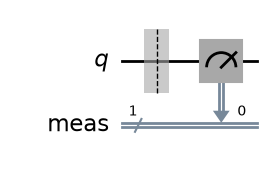

In [152]:
# Initialize Alice at |0>
alice = QuantumCircuit(QUBITS)
alice.measure_all()
alice.draw("mpl")

In [153]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()
result = sampler.run([alice], shots=1024).result()
print(result[0].data.meas.get_counts())

{'0': 1024}


In [154]:
# Set up six different observables.

observables_labels = ["Z", "X", "Y"]
observables = [SparsePauliOp(label) for label in observables_labels]

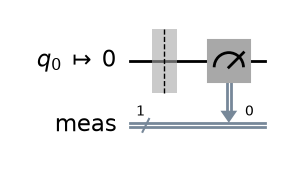

In [163]:
# Convert to an ISA circuit and layout-mapped observables.
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
#isa_circuit_eve = pm.run(eve)
#isa_circuit_bob = pm.run(bob)
isa_circuit_alice = pm.run(alice)

# isa_circuit_eve.draw("mpl", idle_wires=False)
# isa_circuit_bob.draw("mpl", idle_wires=False)
isa_circuit_alice.draw("mpl", idle_wires=False)

In [169]:
# Construct the Estimator instance.
estimator = Estimator(mode=backend)
estimator.options.resilience_level = 1
estimator.options.default_shots = 100

# The observables are 2-qubit Pauli strings, so the circuit must also be 2 qubits.
mapped_observables = [
    observable.apply_layout(isa_circuit_alice.layout) for observable in observables
]

# One pub, with one circuit to run against five different observables.
job_alice = estimator.run([(isa_circuit_alice, mapped_observables)])

# Use the job ID to retrieve your job data later
print(f">>> Job ID: {job_alice.job_id()}")

>>> Job ID: ce0f5351-3f12-4385-8386-98566a8e40c4


In [170]:
# This is the result of the entire submission.  You submitted one Pub,
# so this contains one inner result (and some metadata of its own).
job_result_alice = job_alice.result()

# This is the result from our single pub, which had six observables,
# so contains information on all six.
pub_result_alice = job_result_alice[0]


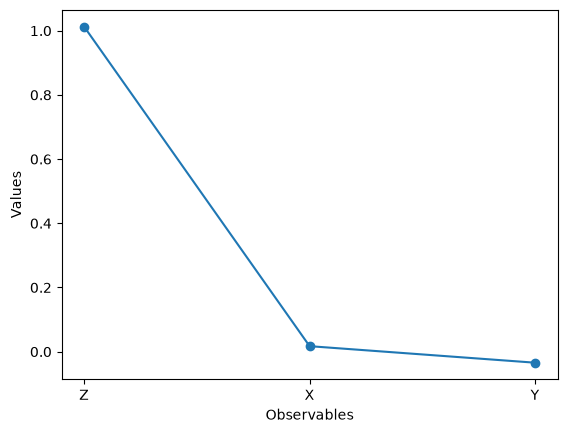

In [171]:
# Plot the result
values_alice = pub_result_alice.data.evs
errors_alice = pub_result_alice.data.stds

# plotting graph
# Each result contains 18 values in the order: [Eve(6), Bob(6), Alice(6)]
alice_values = values_alice[:len(observables_labels)]

plt.plot(observables_labels, alice_values, marker="o", label="Alice")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.show()